<a href="https://colab.research.google.com/github/Sunder1010/smart-waste-classification/blob/main/Smart_Waste_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPU available: []


In [ ]:
!git clone https://github.com/YOUR_USERNAME/smart-waste-classification.git

Cloning into 'smart-waste-classification'...
fatal: could not read Username for 'https://github.com': No such device or address


In [ ]:
!git clone https://github.com/Sunder1010/smart-waste-classification.git

Cloning into 'smart-waste-classification'...
remote: Enumerating objects: 3, done.
remote: Counting objects: 100% (3/3), done.
remote: Compressing objects: 100% (2/2), done.
remote: Total 3 (delta 0), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (3/3), done.


In [ ]:
%cd smart-waste-classification

[Errno 2] No such file or directory: 'smart-waste-classification'
/content/smart-waste-classification


In [ ]:
!ls

README.md


In [ ]:
import os

print("Current directory:")
print(os.getcwd())

print("\nFiles:")
print(os.listdir())

Current directory:
/content/smart-waste-classification

Files:
['README.md', '.git']


In [ ]:
!git status

On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean


In [ ]:
import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: []


In [ ]:
import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
import os

folders = [
    "data",
    "data/raw",
    "data/processed",
    "models",
    "results",
    "sample_images"
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

print("Project folders created successfully!")

Project folders created successfully!


In [ ]:
!find . -maxdepth 2 -type d

.
./.config
./.config/logs
./.config/configurations
./results
./data
./data/processed
./data/raw
./sample_images
./models
./sample_data


In [ ]:
!pip install -q kaggle

In [ ]:
import os

token = os.environ.get("KAGGLE_API_TOKEN")

if token:
    print("Kaggle token is available securely.")
else:
    print("Kaggle token was not found.")

Kaggle token was not found.


In [ ]:
import os

token = os.environ.get("KAGGLE_API_TOKEN")

if token:
    print("Kaggle token is available securely.")
else:
    print("Kaggle token was not found.")

Kaggle token was not found.


In [ ]:
from google.colab import userdata

token = userdata.get("KAGGLE_API_TOKEN")

if token:
    print("Kaggle token is available securely.")
else:
    print("Kaggle token was not found.")

Kaggle token is available securely.


In [ ]:
import os
from google.colab import userdata

os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

print("Kaggle authentication configured.")

Kaggle authentication configured.


In [ ]:
!pip install -q kaggle

In [ ]:
!kaggle datasets list -s garbage-classification

You must authenticate before you can call the Kaggle API.
Follow the instructions to authenticate at: https://github.com/Kaggle/kaggle-cli/blob/main/docs/README.md#authentication


In [ ]:
from google.colab import userdata
import os

token = userdata.get("KAGGLE_API_TOKEN")

if not token:
    raise ValueError("KAGGLE_API_TOKEN was not found in Colab Secrets.")

os.makedirs("/root/.kaggle", exist_ok=True)

with open("/root/.kaggle/access_token", "w") as f:
    f.write(token)

os.chmod("/root/.kaggle/access_token", 0o600)

print("Kaggle credentials configured securely.")

Kaggle credentials configured securely.


In [1]:
!kaggle datasets list -s garbage-classification

You must authenticate before you can call the Kaggle API.
Follow the instructions to authenticate at: https://github.com/Kaggle/kaggle-cli/blob/main/docs/README.md#authentication


In [2]:
!pip install -q kagglehub

In [3]:
import kagglehub

dataset_path = kagglehub.dataset_download(
    "mostafaabla/garbage-classification"
)

print("Dataset downloaded to:")
print(dataset_path)

Using Colab cache for faster access to the 'garbage-classification' dataset.
Dataset downloaded to:
/kaggle/input/garbage-classification


In [5]:
import os

print("Dataset contents:")

for item in os.listdir(dataset_path):
    print(item)

Dataset contents:
garbage_classification


In [6]:
for root, dirs, files in os.walk(dataset_path):
    level = root.replace(dataset_path, "").count(os.sep)

    if level <= 1:
        print(
            "  " * level +
            f"{os.path.basename(root)}/ "
            f"({len(files)} images)"
        )

garbage-classification/ (0 images)
  garbage_classification/ (0 images)


In [7]:
!pip install -q kagglehub

In [8]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image

print("Libraries imported successfully!")

Libraries imported successfully!


In [9]:
from pathlib import Path

dataset_root = Path(dataset_path)

image_extensions = {".jpg", ".jpeg", ".png", ".webp"}

class_dirs = []

for folder in dataset_root.rglob("*"):
    if folder.is_dir():
        images = [
            f for f in folder.iterdir()
            if f.is_file() and f.suffix.lower() in image_extensions
        ]

        if len(images) > 0:
            class_dirs.append(folder)

print("Found class folders:")
for folder in class_dirs:
    print(folder)

Found class folders:
/kaggle/input/garbage-classification/garbage_classification/metal
/kaggle/input/garbage-classification/garbage_classification/white-glass
/kaggle/input/garbage-classification/garbage_classification/biological
/kaggle/input/garbage-classification/garbage_classification/paper
/kaggle/input/garbage-classification/garbage_classification/brown-glass
/kaggle/input/garbage-classification/garbage_classification/battery
/kaggle/input/garbage-classification/garbage_classification/trash
/kaggle/input/garbage-classification/garbage_classification/cardboard
/kaggle/input/garbage-classification/garbage_classification/shoes
/kaggle/input/garbage-classification/garbage_classification/clothes
/kaggle/input/garbage-classification/garbage_classification/plastic
/kaggle/input/garbage-classification/garbage_classification/green-glass


In [10]:
class_counts = {}

for folder in class_dirs:
    count = sum(
        1 for f in folder.iterdir()
        if f.is_file() and f.suffix.lower() in image_extensions
    )

    class_counts[folder.name] = count

class_counts

{'metal': 769,
 'white-glass': 775,
 'biological': 985,
 'paper': 1050,
 'brown-glass': 607,
 'battery': 945,
 'trash': 697,
 'cardboard': 891,
 'shoes': 1977,
 'clothes': 5325,
 'plastic': 865,
 'green-glass': 629}

In [11]:
class_counts_df = pd.DataFrame(
    list(class_counts.items()),
    columns=["Class", "Images"]
)

class_counts_df = class_counts_df.sort_values(
    "Images",
    ascending=False
)

print(class_counts_df)

          Class  Images
9       clothes    5325
8         shoes    1977
3         paper    1050
2    biological     985
5       battery     945
7     cardboard     891
10      plastic     865
1   white-glass     775
0         metal     769
6         trash     697
11  green-glass     629
4   brown-glass     607


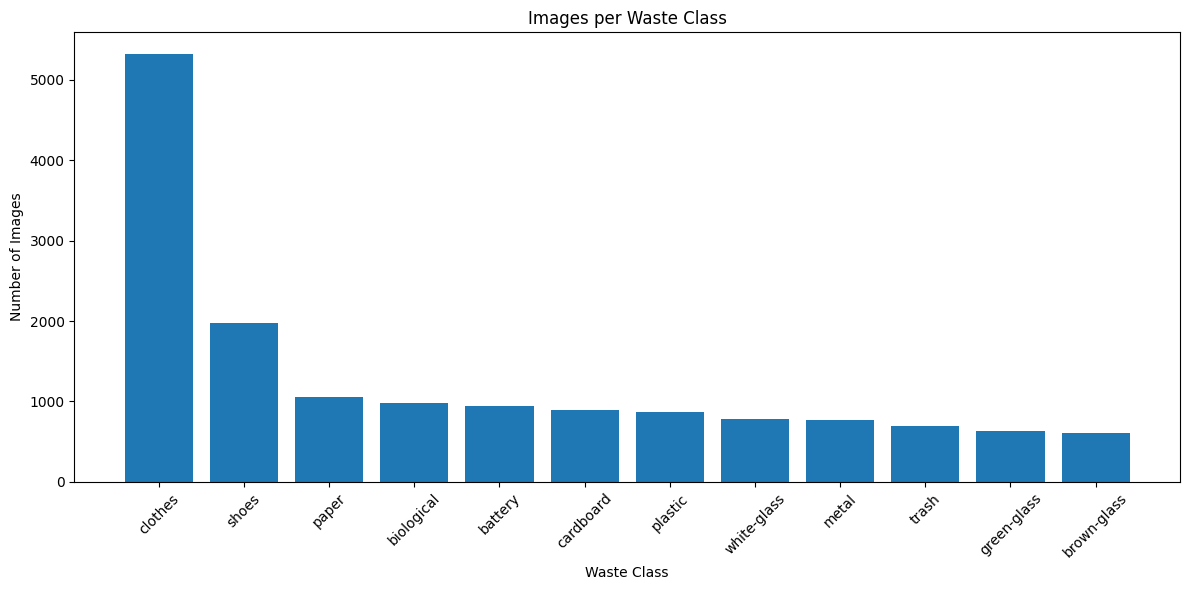

In [12]:
plt.figure(figsize=(12, 6))

plt.bar(
    class_counts_df["Class"],
    class_counts_df["Images"]
)

plt.xlabel("Waste Class")
plt.ylabel("Number of Images")
plt.title("Images per Waste Class")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

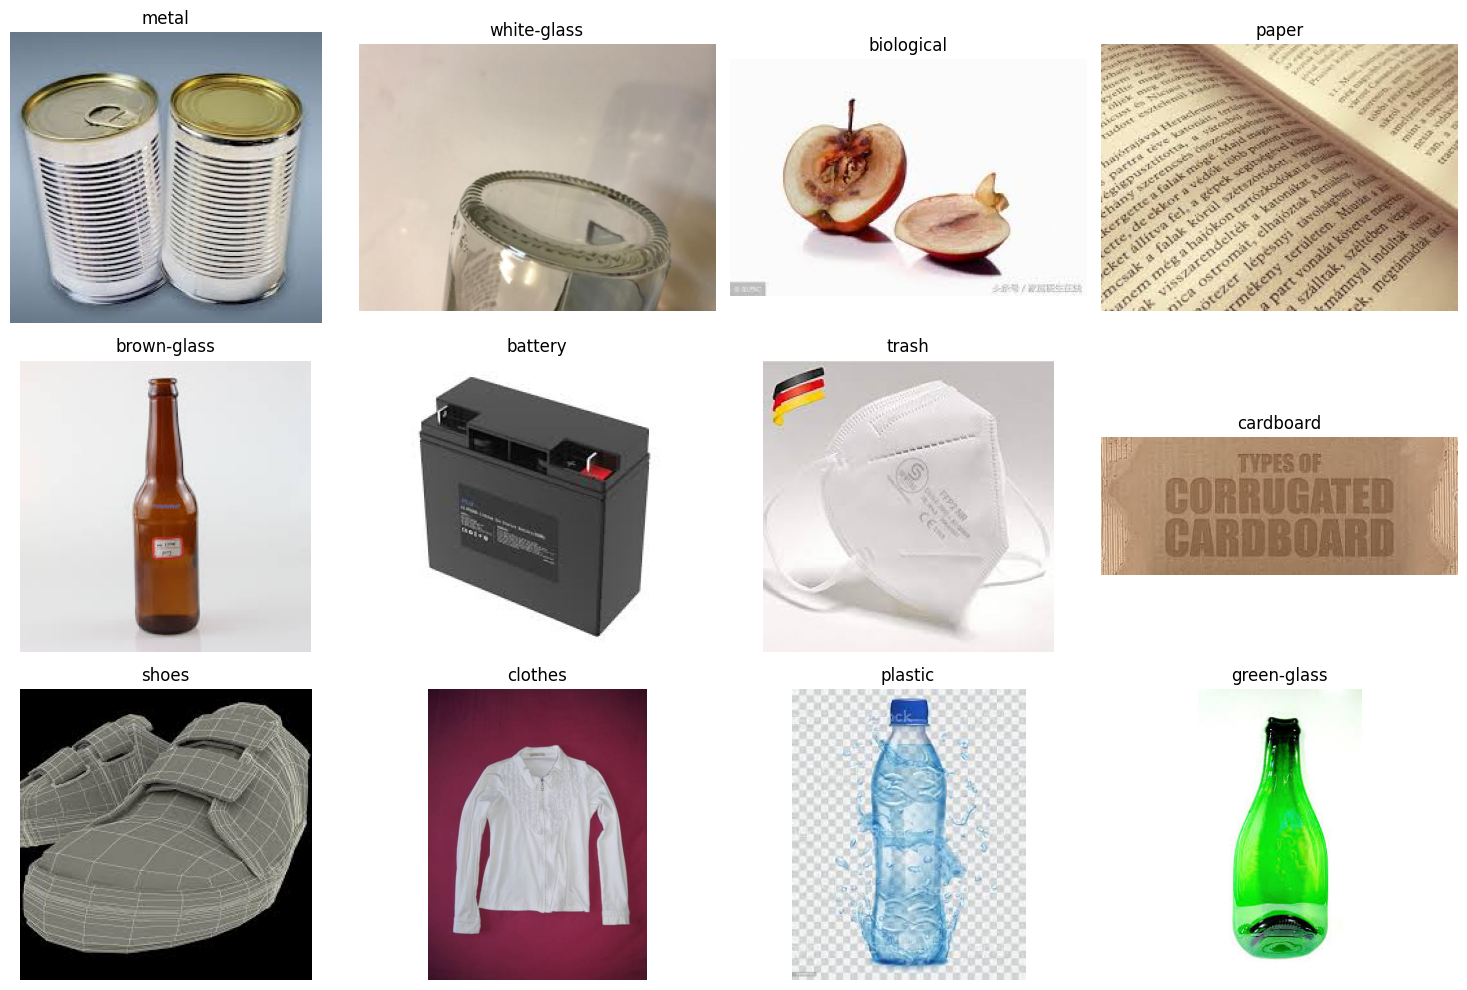

In [13]:
import random

plt.figure(figsize=(15, 10))

for i, folder in enumerate(class_dirs):

    images = [
        f for f in folder.iterdir()
        if f.is_file() and f.suffix.lower() in image_extensions
    ]

    image_file = random.choice(images)
    image = Image.open(image_file)

    plt.subplot(3, 4, i + 1)
    plt.imshow(image)
    plt.title(folder.name)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [14]:
sizes = []

for folder in class_dirs:
    images = [
        f for f in folder.iterdir()
        if f.is_file() and f.suffix.lower() in image_extensions
    ]

    # Check first 100 images per class
    for image_file in images[:100]:
        try:
            with Image.open(image_file) as img:
                sizes.append(img.size)
        except:
            pass

print("Number of images checked:", len(sizes))
print("First 20 image sizes:")
print(sizes[:20])

Number of images checked: 1200
First 20 image sizes:
[(512, 384), (225, 225), (512, 384), (306, 164), (512, 384), (512, 384), (512, 384), (225, 225), (275, 183), (225, 225), (512, 384), (225, 225), (512, 384), (512, 384), (512, 384), (225, 225), (512, 384), (225, 225), (225, 225), (250, 199)]


In [15]:
unique_sizes = len(set(sizes))

print("Unique image sizes:", unique_sizes)

Unique image sizes: 210


In [16]:
from pathlib import Path
import pandas as pd

image_extensions = {".jpg", ".jpeg", ".png", ".webp"}

image_paths = []
labels = []

for class_dir in class_dirs:
    for image_file in class_dir.iterdir():

        if image_file.is_file() and image_file.suffix.lower() in image_extensions:
            image_paths.append(str(image_file))
            labels.append(class_dir.name)

df = pd.DataFrame({
    "filepath": image_paths,
    "label": labels
})

print("Total images:", len(df))
print("Total classes:", df["label"].nunique())

df.head()

Total images: 15515
Total classes: 12


,filepath,label
0,/kaggle/input/garbage-classification/garbage_c...,metal
1,/kaggle/input/garbage-classification/garbage_c...,metal
2,/kaggle/input/garbage-classification/garbage_c...,metal
3,/kaggle/input/garbage-classification/garbage_c...,metal
4,/kaggle/input/garbage-classification/garbage_c...,metal


In [17]:
print(df["label"].value_counts())

label
clothes        5325
shoes          1977
paper          1050
biological      985
battery         945
cardboard       891
plastic         865
white-glass     775
metal           769
trash           697
green-glass     629
brown-glass     607
Name: count, dtype: int64


In [18]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42,
    stratify=df["label"]
)

print("Training images:", len(train_df))
print("Temporary images:", len(temp_df))

Training images: 10860
Temporary images: 4655


In [19]:
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["label"]
)

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Training: 10860
Validation: 2327
Test: 2328


In [20]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
NUM_CLASSES = df["label"].nunique()

print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Number of classes:", NUM_CLASSES)

Image size: (224, 224)
Batch size: 32
Number of classes: 12


In [21]:
class_names = sorted(df["label"].unique())

class_to_index = {
    class_name: index
    for index, class_name in enumerate(class_names)
}

index_to_class = {
    index: class_name
    for class_name, index in class_to_index.items()
}

print("Class mapping:")

for index, class_name in index_to_class.items():
    print(index, "→", class_name)

Class mapping:
0 → battery
1 → biological
2 → brown-glass
3 → cardboard
4 → clothes
5 → green-glass
6 → metal
7 → paper
8 → plastic
9 → shoes
10 → trash
11 → white-glass


In [23]:
import tensorflow as tf

def load_and_preprocess_image(filepath, label):

    # Read image file
    image = tf.io.read_file(filepath)

    # Decode JPEG/PNG image
    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    # Resize
    image = tf.image.resize(
        image,
        IMG_SIZE
    )

    # Convert pixel values from 0-255 to 0-1
    image = tf.cast(image, tf.float32) / 255.0

    return image, label

In [24]:
train_labels = train_df["label"].map(class_to_index).values
val_labels = val_df["label"].map(class_to_index).values
test_labels = test_df["label"].map(class_to_index).values

In [26]:
def create_dataset(dataframe, labels, shuffle=False):

    paths = dataframe["filepath"].values

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    dataset = dataset.map(
        load_and_preprocess_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=1000,
            seed=42
        )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset

In [27]:
train_ds = create_dataset(
    train_df,
    train_labels,
    shuffle=True
)

val_ds = create_dataset(
    val_df,
    val_labels
)

test_ds = create_dataset(
    test_df,
    test_labels
)

In [28]:
images, labels = next(iter(train_ds))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Pixel minimum:", tf.reduce_min(images).numpy())
print("Pixel maximum:", tf.reduce_max(images).numpy())

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Pixel minimum: 0.0
Pixel maximum: 1.0


In [29]:
from tensorflow.keras import layers, models

In [30]:
cnn_model = models.Sequential([

    layers.Input(shape=(224, 224, 3)),

    # Block 1
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Block 2
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Block 3
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Classification
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    # Output
    layers.Dense(NUM_CLASSES, activation="softmax")
])

In [31]:
cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [32]:
cnn_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 12)             │         1,548 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,170,508 (42.61 MB)

 Trainable params: 11,170,508 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [33]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-6
    ),

    ModelCheckpoint(
        "best_cnn_model.keras",
        monitor="val_accuracy",
        save_best_only=True
    )
]

In [34]:
history_cnn = cnn_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks
)

Epoch 1/10
340/340 ━━━━━━━━━━━━━━━━━━━━ 60s 140ms/step - accuracy: 0.4878 - loss: 1.5946 - val_accuracy: 0.6304 - val_loss: 1.1243 - learning_rate: 0.0010
Epoch 2/10
340/340 ━━━━━━━━━━━━━━━━━━━━ 26s 73ms/step - accuracy: 0.6275 - loss: 1.1680 - val_accuracy: 0.6691 - val_loss: 1.0319 - learning_rate: 0.0010
Epoch 3/10
340/340 ━━━━━━━━━━━━━━━━━━━━ 42s 75ms/step - accuracy: 0.6844 - loss: 0.9737 - val_accuracy: 0.6962 - val_loss: 0.9350 - learning_rate: 0.0010
Epoch 4/10
340/340 ━━━━━━━━━━━━━━━━━━━━ 39s 70ms/step - accuracy: 0.7375 - loss: 0.8112 - val_accuracy: 0.7168 - val_loss: 0.9096 - learning_rate: 0.0010
Epoch 5/10
340/340 ━━━━━━━━━━━━━━━━━━━━ 25s 71ms/step - accuracy: 0.7825 - loss: 0.6666 - val_accuracy: 0.7284 - val_loss: 0.9109 - learning_rate: 0.0010
Epoch 6/10
340/340 ━━━━━━━━━━━━━━━━━━━━ 25s 70ms/step - accuracy: 0.8081 - loss: 0.5708 - val_accuracy: 0.7323 - val_loss: 0.9725 - learning_rate: 0.0010
Epoch 7/10
340/340 ━━━━━━━━━━━━━━━━━━━━ 25s 71ms/step - accuracy: 0.8731 - 

In [35]:
print(tf.config.list_physical_devices("GPU"))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


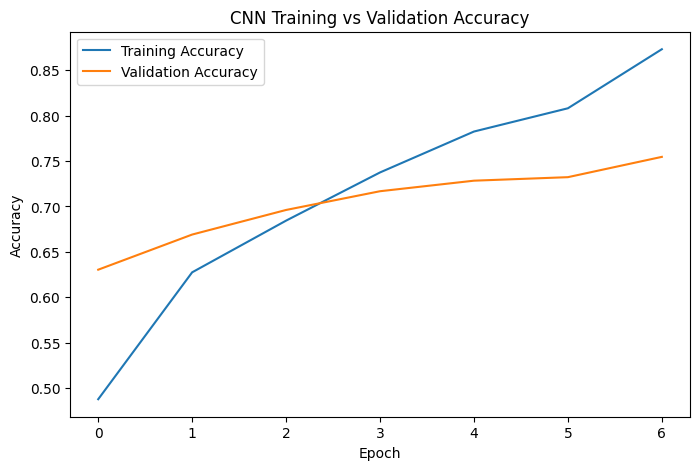

In [36]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(history_cnn.history["accuracy"], label="Training Accuracy")
plt.plot(history_cnn.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Training vs Validation Accuracy")
plt.legend()
plt.show()

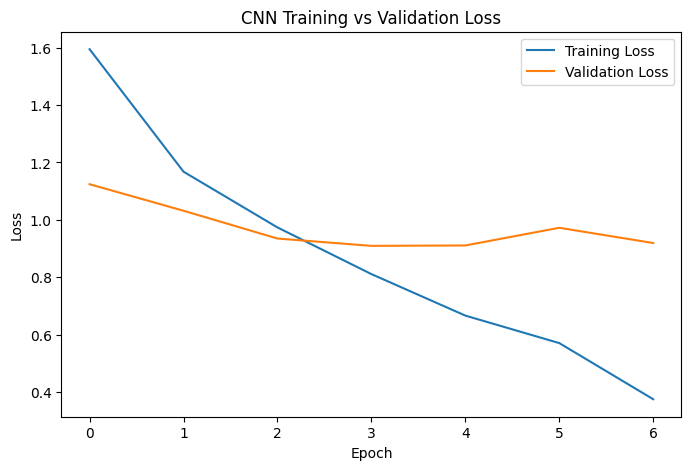

In [37]:
plt.figure(figsize=(8, 5))

plt.plot(history_cnn.history["loss"], label="Training Loss")
plt.plot(history_cnn.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Training vs Validation Loss")
plt.legend()
plt.show()

In [38]:
test_loss, test_accuracy = cnn_model.evaluate(test_ds)

print("CNN Test Loss:", test_loss)
print("CNN Test Accuracy:", test_accuracy)

73/73 ━━━━━━━━━━━━━━━━━━━━ 9s 117ms/step - accuracy: 0.7470 - loss: 0.8771
CNN Test Loss: 0.8770915269851685
CNN Test Accuracy: 0.7469931244850159


In [39]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

In [40]:
y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = cnn_model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

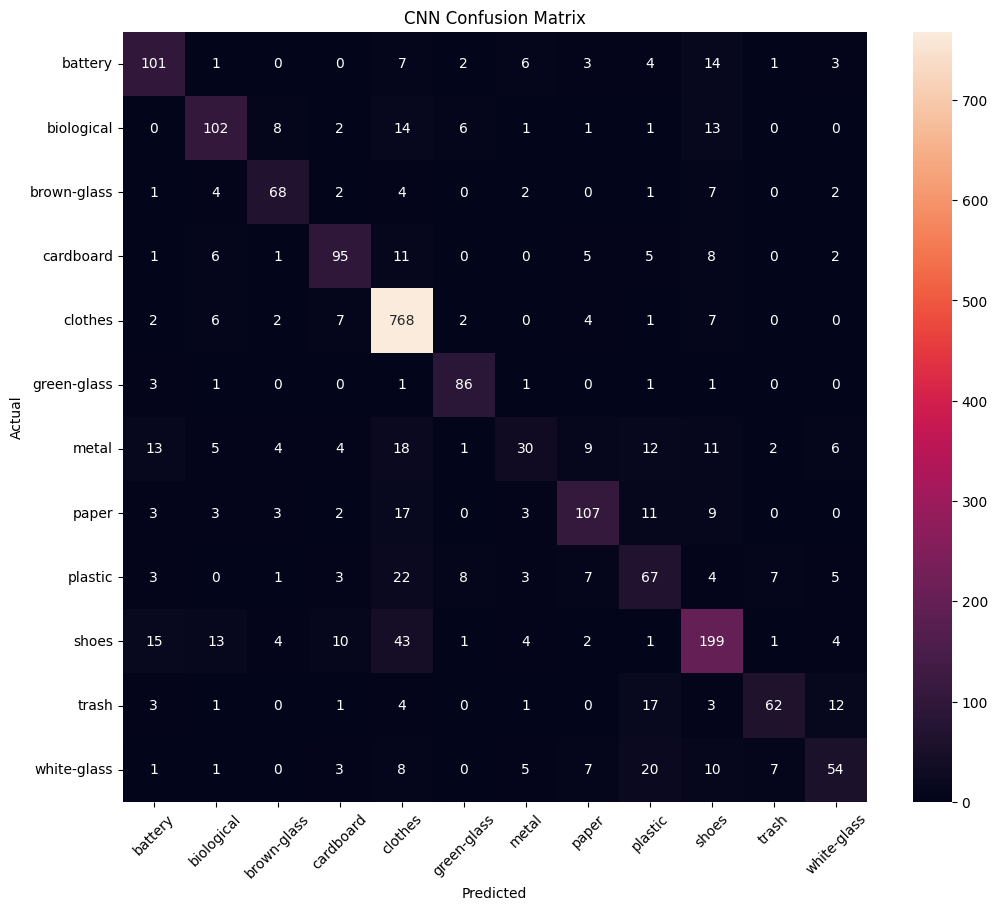

In [41]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(12, 10))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("CNN Confusion Matrix")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.show()

In [42]:
print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names
    )
)

              precision    recall  f1-score   support

     battery       0.69      0.71      0.70       142
  biological       0.71      0.69      0.70       148
 brown-glass       0.75      0.75      0.75        91
   cardboard       0.74      0.71      0.72       134
     clothes       0.84      0.96      0.90       799
 green-glass       0.81      0.91      0.86        94
       metal       0.54      0.26      0.35       115
       paper       0.74      0.68      0.71       158
     plastic       0.48      0.52      0.49       130
       shoes       0.70      0.67      0.68       297
       trash       0.78      0.60      0.67       104
 white-glass       0.61      0.47      0.53       116

    accuracy                           0.75      2328
   macro avg       0.70      0.66      0.67      2328
weighted avg       0.74      0.75      0.74      2328



In [43]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, models

base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [44]:
mobilenet_model = models.Sequential([

    layers.Input(shape=(224, 224, 3)),

    layers.Rescaling(
        scale=2.0,
        offset=-1.0
    ),

    base_model,

    layers.GlobalAveragePooling2D(),

    layers.Dense(
        128,
        activation="relu"
    ),

    layers.Dropout(0.5),

    layers.Dense(
        NUM_CLASSES,
        activation="softmax"
    )
])

In [45]:
mobilenet_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [46]:
mobilenet_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 12)             │         1,548 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,423,500 (9.24 MB)

 Trainable params: 165,516 (646.55 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [48]:
mobilenet_callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-6
    ),

    ModelCheckpoint(
        "best_mobilenetv2.keras",
        monitor="val_accuracy",
        save_best_only=True
    )
]

In [49]:
history_mobilenet = mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=mobilenet_callbacks
)

Epoch 1/10
340/340 ━━━━━━━━━━━━━━━━━━━━ 45s 88ms/step - accuracy: 0.8355 - loss: 0.5500 - val_accuracy: 0.9330 - val_loss: 0.2017 - learning_rate: 0.0010
Epoch 2/10
340/340 ━━━━━━━━━━━━━━━━━━━━ 20s 54ms/step - accuracy: 0.9227 - loss: 0.2523 - val_accuracy: 0.9398 - val_loss: 0.1795 - learning_rate: 0.0010
Epoch 3/10
340/340 ━━━━━━━━━━━━━━━━━━━━ 20s 55ms/step - accuracy: 0.9380 - loss: 0.1961 - val_accuracy: 0.9446 - val_loss: 0.1744 - learning_rate: 0.0010
Epoch 4/10
340/340 ━━━━━━━━━━━━━━━━━━━━ 21s 57ms/step - accuracy: 0.9498 - loss: 0.1526 - val_accuracy: 0.9489 - val_loss: 0.1558 - learning_rate: 0.0010
Epoch 5/10
340/340 ━━━━━━━━━━━━━━━━━━━━ 22s 62ms/step - accuracy: 0.9566 - loss: 0.1304 - val_accuracy: 0.9493 - val_loss: 0.1509 - learning_rate: 0.0010
Epoch 6/10
340/340 ━━━━━━━━━━━━━━━━━━━━ 21s 57ms/step - accuracy: 0.9629 - loss: 0.1080 - val_accuracy: 0.9527 - val_loss: 0.1589 - learning_rate: 0.0010
Epoch 7/10
340/340 ━━━━━━━━━━━━━━━━━━━━ 19s 52ms/step - accuracy: 0.9649 - l

In [50]:
mobile_loss, mobile_accuracy = mobilenet_model.evaluate(test_ds)

print("MobileNetV2 Test Loss:", mobile_loss)
print("MobileNetV2 Test Accuracy:", mobile_accuracy)

73/73 ━━━━━━━━━━━━━━━━━━━━ 11s 145ms/step - accuracy: 0.9510 - loss: 0.1845
MobileNetV2 Test Loss: 0.18449388444423676
MobileNetV2 Test Accuracy: 0.9510309100151062


In [51]:
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

In [52]:
from tensorflow.keras.optimizers import Adam

mobilenet_model.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [53]:
history_finetune = mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=mobilenet_callbacks
)

Epoch 1/5
340/340 ━━━━━━━━━━━━━━━━━━━━ 57s 117ms/step - accuracy: 0.9281 - loss: 0.2278 - val_accuracy: 0.9557 - val_loss: 0.1583 - learning_rate: 1.0000e-05
Epoch 2/5
340/340 ━━━━━━━━━━━━━━━━━━━━ 20s 55ms/step - accuracy: 0.9478 - loss: 0.1551 - val_accuracy: 0.9562 - val_loss: 0.1586 - learning_rate: 1.0000e-05
Epoch 3/5
340/340 ━━━━━━━━━━━━━━━━━━━━ 20s 55ms/step - accuracy: 0.9592 - loss: 0.1280 - val_accuracy: 0.9544 - val_loss: 0.1538 - learning_rate: 2.0000e-06


In [54]:
final_loss, final_accuracy = mobilenet_model.evaluate(test_ds)

print("Final Test Loss:", final_loss)
print("Final Test Accuracy:", final_accuracy)

73/73 ━━━━━━━━━━━━━━━━━━━━ 5s 74ms/step - accuracy: 0.9472 - loss: 0.1987
Final Test Loss: 0.19865907728672028
Final Test Accuracy: 0.9471649527549744


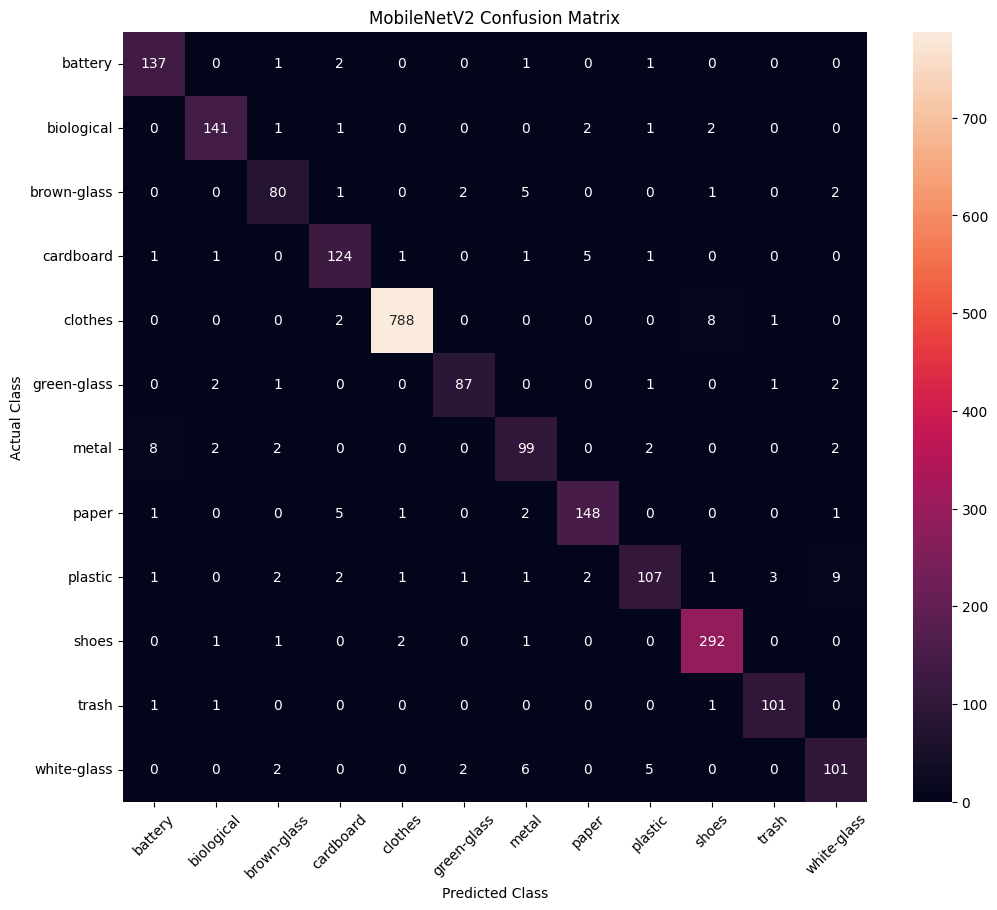

In [57]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = mobilenet_model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(12, 10))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("MobileNetV2 Confusion Matrix")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.show()

In [58]:
print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names
    )
)

              precision    recall  f1-score   support

     battery       0.92      0.96      0.94       142
  biological       0.95      0.95      0.95       148
 brown-glass       0.89      0.88      0.88        91
   cardboard       0.91      0.93      0.92       134
     clothes       0.99      0.99      0.99       799
 green-glass       0.95      0.93      0.94        94
       metal       0.85      0.86      0.86       115
       paper       0.94      0.94      0.94       158
     plastic       0.91      0.82      0.86       130
       shoes       0.96      0.98      0.97       297
       trash       0.95      0.97      0.96       104
 white-glass       0.86      0.87      0.87       116

    accuracy                           0.95      2328
   macro avg       0.92      0.92      0.92      2328
weighted avg       0.95      0.95      0.95      2328



In [59]:
from google.colab import files

uploaded = files.upload()

Saving testimage.jpg to testimage.jpg


In [60]:
image_path = list(uploaded.keys())[0]

img = tf.keras.utils.load_img(
    image_path,
    target_size=(224, 224)
)

img_array = tf.keras.utils.img_to_array(img)

# Normalize image
img_array = img_array / 255.0

# Add batch dimension
img_array = np.expand_dims(img_array, axis=0)

# Prediction
prediction = mobilenet_model.predict(img_array)

predicted_index = np.argmax(prediction[0])

predicted_class = class_names[predicted_index]

confidence = prediction[0][predicted_index]

print("Predicted Class:", predicted_class)
print("Confidence:", f"{confidence * 100:.2f}%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 6s 6s/step
Predicted Class: white-glass
Confidence: 99.59%


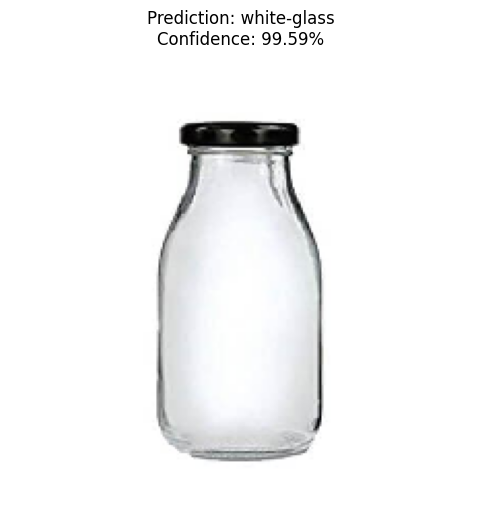

In [61]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(6, 6))

plt.imshow(img)
plt.axis("off")

plt.title(
    f"Prediction: {predicted_class}\n"
    f"Confidence: {confidence * 100:.2f}%"
)

plt.show()

In [62]:
top_3_indices = np.argsort(prediction[0])[-3:][::-1]

print("Top 3 Predictions:\n")

for i in top_3_indices:
    print(
        f"{class_names[i]}: "
        f"{prediction[0][i] * 100:.2f}%"
    )

Top 3 Predictions:

white-glass: 99.59%
plastic: 0.29%
green-glass: 0.08%


In [63]:
mobilenet_model.save("smart_waste_mobilenetv2.keras")

print("Model saved successfully!")

Model saved successfully!


In [64]:
import json

with open("class_names.json", "w") as f:
    json.dump(class_names, f)

print("Class names saved successfully!")

Class names saved successfully!


In [65]:
results = {
    "Model": [
        "Custom CNN",
        "MobileNetV2 Transfer Learning"
    ],
    "Test Accuracy": [
        cnn_test_accuracy if "cnn_test_accuracy" in globals() else None,
        final_accuracy
    ]
}

print(results)

{'Model': ['Custom CNN', 'MobileNetV2 Transfer Learning'], 'Test Accuracy': [None, 0.9471649527549744]}


In [66]:
cnn_loss, cnn_accuracy = cnn_model.evaluate(test_ds)

print("CNN Accuracy:", cnn_accuracy)
print("MobileNetV2 Accuracy:", final_accuracy)

73/73 ━━━━━━━━━━━━━━━━━━━━ 4s 52ms/step - accuracy: 0.7470 - loss: 0.8771
CNN Accuracy: 0.7469931244850159
MobileNetV2 Accuracy: 0.9471649527549744


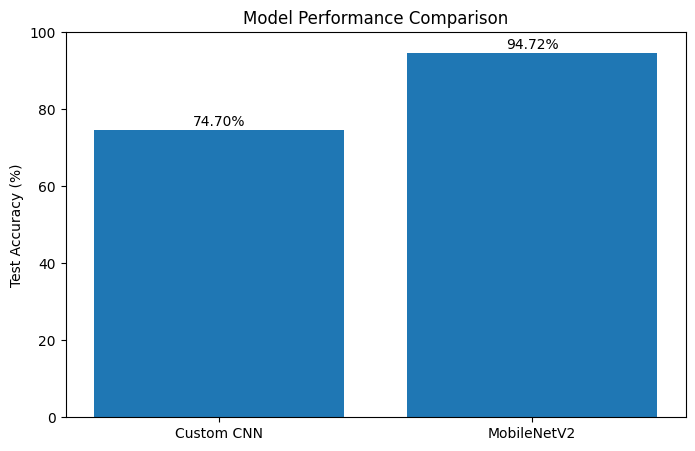

In [67]:
models = ["Custom CNN", "MobileNetV2"]

accuracies = [
    cnn_accuracy * 100,
    final_accuracy * 100
]

plt.figure(figsize=(8, 5))

bars = plt.bar(models, accuracies)

plt.ylabel("Test Accuracy (%)")
plt.title("Model Performance Comparison")
plt.ylim(0, 100)

for bar, value in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 1,
        f"{value:.2f}%",
        ha="center"
    )

plt.show()